### Automobile Dataset: Machine Learning Workflow

This notebook explores an automobile dataset using basic machine learning techniques. The dataset contains information about individuals, including demographic and financial features, and whether they have taken certain types of loans, such as new house loans or personal loans.

The goal is to build a classification model using machine learning to predict loan decisions based on available features like:

    Age_Group
    Dependents_Group
    Price_Range
    Salary_Group

We will use Logistic Regression as our primary model to:

    Train and test a classifier
    Evaluate its performance using classification metrics (accuracy, precision, recall, F1-score)
    Visualise the model performance with ROC Curve and AUC Score
    Understand the effect of class imbalance and how to adjust for it

Step-by-Step Process:

    Load and inspect the dataset
    Preprocess the data (handle missing values, encode categorical variables if necessary)
    Split the dataset into training and testing sets
    Train a classification model (Logistic Regression)
    Evaluate the model using confusion matrix and classification report
    Visualise ROC-AUC and tune decision threshold
    Interpret results and summarise findings

# Import Libraries

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib  as plt
%matplotlib inline

# Load Dataset

In [5]:
dataset = pd.read_csv("automobile.csv")
display(dataset)

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
0,24,Male,Salaried,Married,Post Graduate,4,No,Yes,Yes,52000,25000,77000,18000,Hatchback
1,28,Male,Salaried,Married,Post Graduate,3,No,Yes,No,68000,0,68000,18000,Hatchback
2,23,Male,Salaried,Married,Graduate,4,Yes,Yes,No,31000,0,31000,18000,Hatchback
3,26,Male,Business,Married,Post Graduate,4,Yes,Yes,Yes,66000,35000,101000,18000,Hatchback
4,28,Male,Business,Married,Post Graduate,4,Yes,No,No,64000,0,64000,18000,Hatchback
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1576,28,Male,Salaried,Married,Post Graduate,2,Yes,No,No,72000,0,72000,33000,Hatchback
1577,23,Male,Salaried,Single,Graduate,2,Yes,Yes,No,37000,0,37000,33000,Hatchback
1578,23,Male,Business,Married,Graduate,4,Yes,Yes,Yes,38000,28000,66000,33000,Hatchback
1579,25,Male,Business,Married,Post Graduate,3,Yes,Yes,Yes,58000,40000,98000,33000,Hatchback


# Check total missing values in the dataset

In [7]:
dataset.isnull().values.sum()

0

# Check data types of each column

In [9]:
print("\nData types of each column:")
print(dataset.dtypes)


Data types of each column:
Age                  int64
Gender              object
Profession          object
Marital_status      object
Education           object
No_of_Dependents     int64
Personal_loan       object
House_loan          object
Partner_working     object
Salary               int64
Partner_salary       int64
Total_salary         int64
Price                int64
Make                object
dtype: object


# Check number of rows and columns

In [11]:
rows, columns = dataset.shape
print(f"\nNumber of rows: {rows}")
print(f"Number of columns: {columns}")


Number of rows: 1581
Number of columns: 14


# Demographic Analysis
Demographic analysis helps in understanding the composition of individuals represented in the dataset. It provides insights into key socio-economic attributes such as gender, marital status, education, profession, and whether individuals have personal or house loans. By exploring these categorical features, we can identify patterns, biases, or distributions that may influence consumer behavior or loan eligibility. Visualising these distributions allows for better intuition and guides appropriate preprocessing or feature engineering for machine learning tasks.

# Display summary statistics

In [14]:
# Select numerical columns
numerical_columns = dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Summary statistics of numerical features:")
print(dataset[numerical_columns].describe())

Summary statistics of numerical features:
               Age  No_of_Dependents        Salary  Partner_salary  \
count  1581.000000       1581.000000   1581.000000     1581.000000   
mean     32.211259          2.457938  59732.447818    19720.430108   
std       9.125477          0.943483  14278.642665    19480.214404   
min      22.000000          0.000000  30000.000000        0.000000   
25%      25.000000          2.000000  51000.000000        0.000000   
50%      29.000000          2.000000  59000.000000    25000.000000   
75%      38.000000          3.000000  71000.000000    38000.000000   
max      60.000000          4.000000  90000.000000    80000.000000   

        Total_salary         Price  
count    1581.000000   1581.000000  
mean    79452.877925  35597.722960  
std     24855.936043  13633.636545  
min     30000.000000  18000.000000  
25%     61000.000000  25000.000000  
50%     78000.000000  31000.000000  
75%     96000.000000  47000.000000  
max    158000.000000  70000.000

# Visualise distributions

In [16]:
# List of categorical columns
categorical_columns = ['Make', 'Gender', 'Profession', 'Marital_status', 'Education', 'Personal_loan', 'House_loan', 'Partner_working']

# Loop through each column and print normalized value counts
for col in categorical_columns:
    print(f"\nValue counts for '{col}':")
    print(dataset[col].value_counts(normalize=False))


Value counts for 'Make':
Make
Hatchback    884
Sedan        460
SUV          237
Name: count, dtype: int64

Value counts for 'Gender':
Gender
Male      1252
Female     329
Name: count, dtype: int64

Value counts for 'Profession':
Profession
Salaried    896
Business    685
Name: count, dtype: int64

Value counts for 'Marital_status':
Marital_status
Married    1443
Single      138
Name: count, dtype: int64

Value counts for 'Education':
Education
Post Graduate    985
Graduate         596
Name: count, dtype: int64

Value counts for 'Personal_loan':
Personal_loan
Yes    792
No     789
Name: count, dtype: int64

Value counts for 'House_loan':
House_loan
No     1054
Yes     527
Name: count, dtype: int64

Value counts for 'Partner_working':
Partner_working
Yes    868
No     713
Name: count, dtype: int64


C:\Users\VICTOR\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\VICTOR\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\VICTOR\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\VICTOR\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

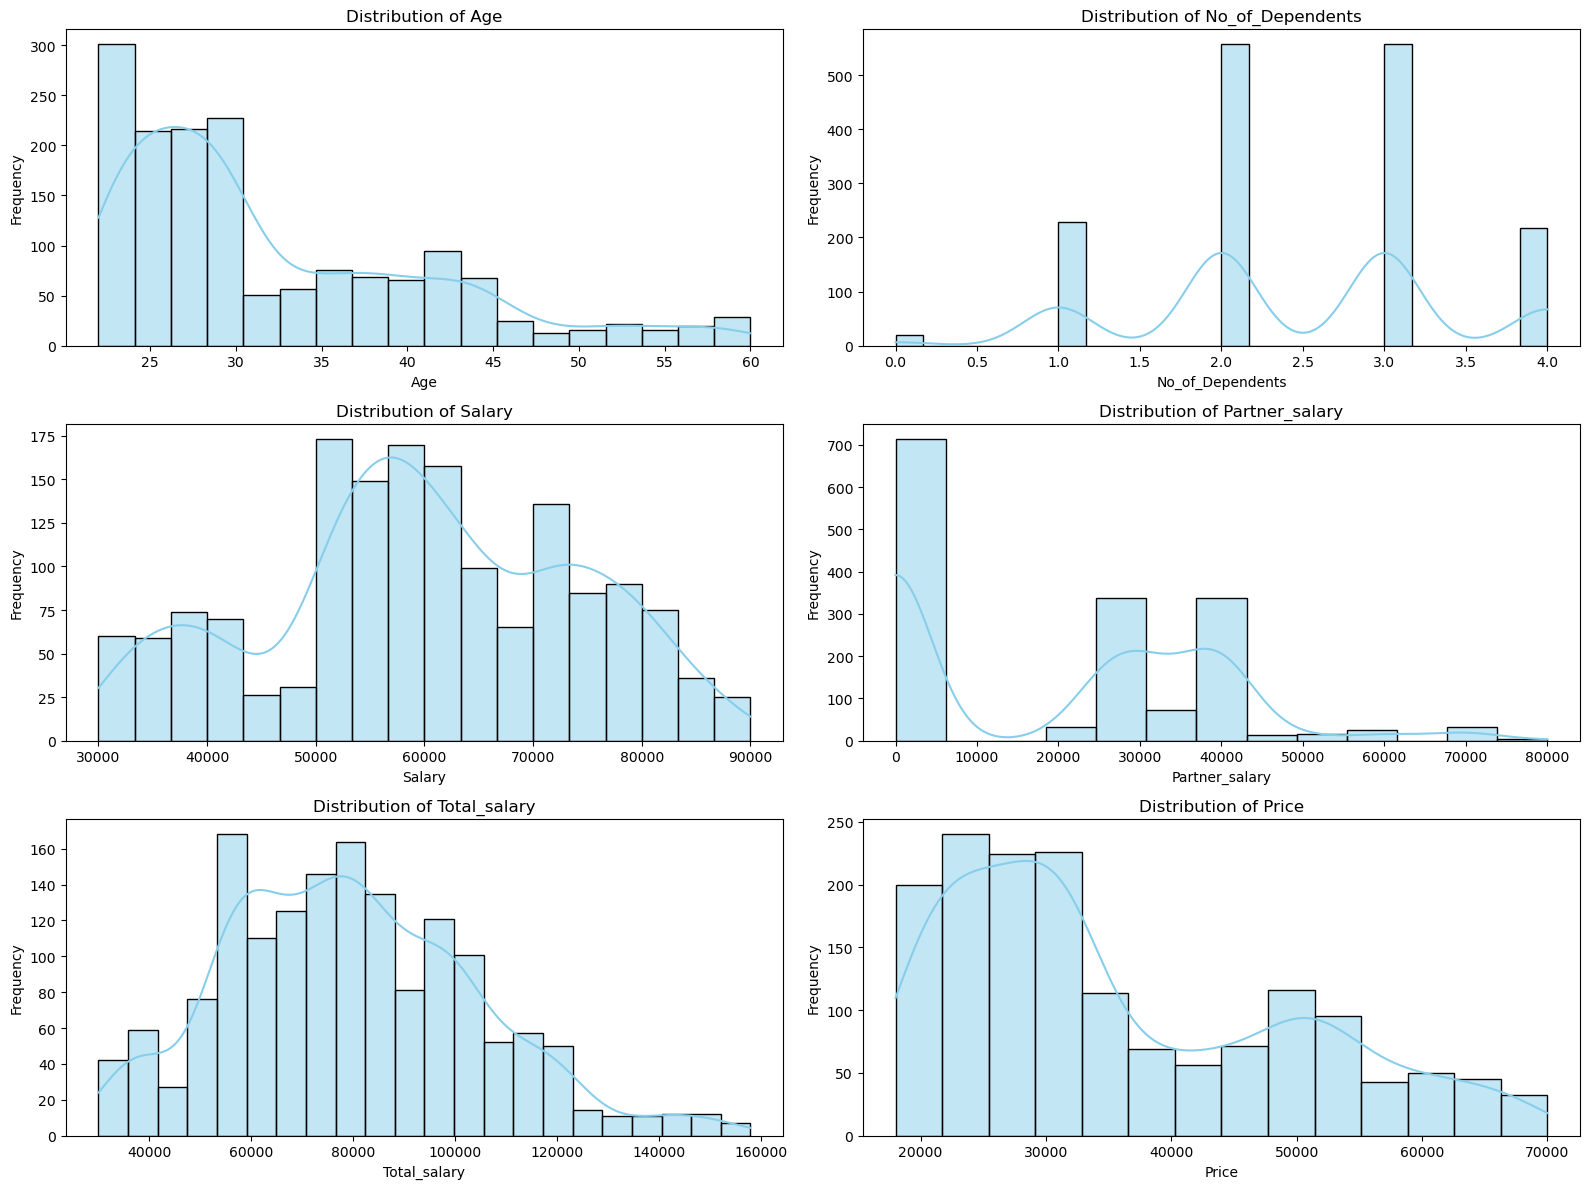

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

n_cols = 2
n_rows = -(-len(numerical_columns) // n_cols)  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.histplot(dataset[col].dropna(), kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

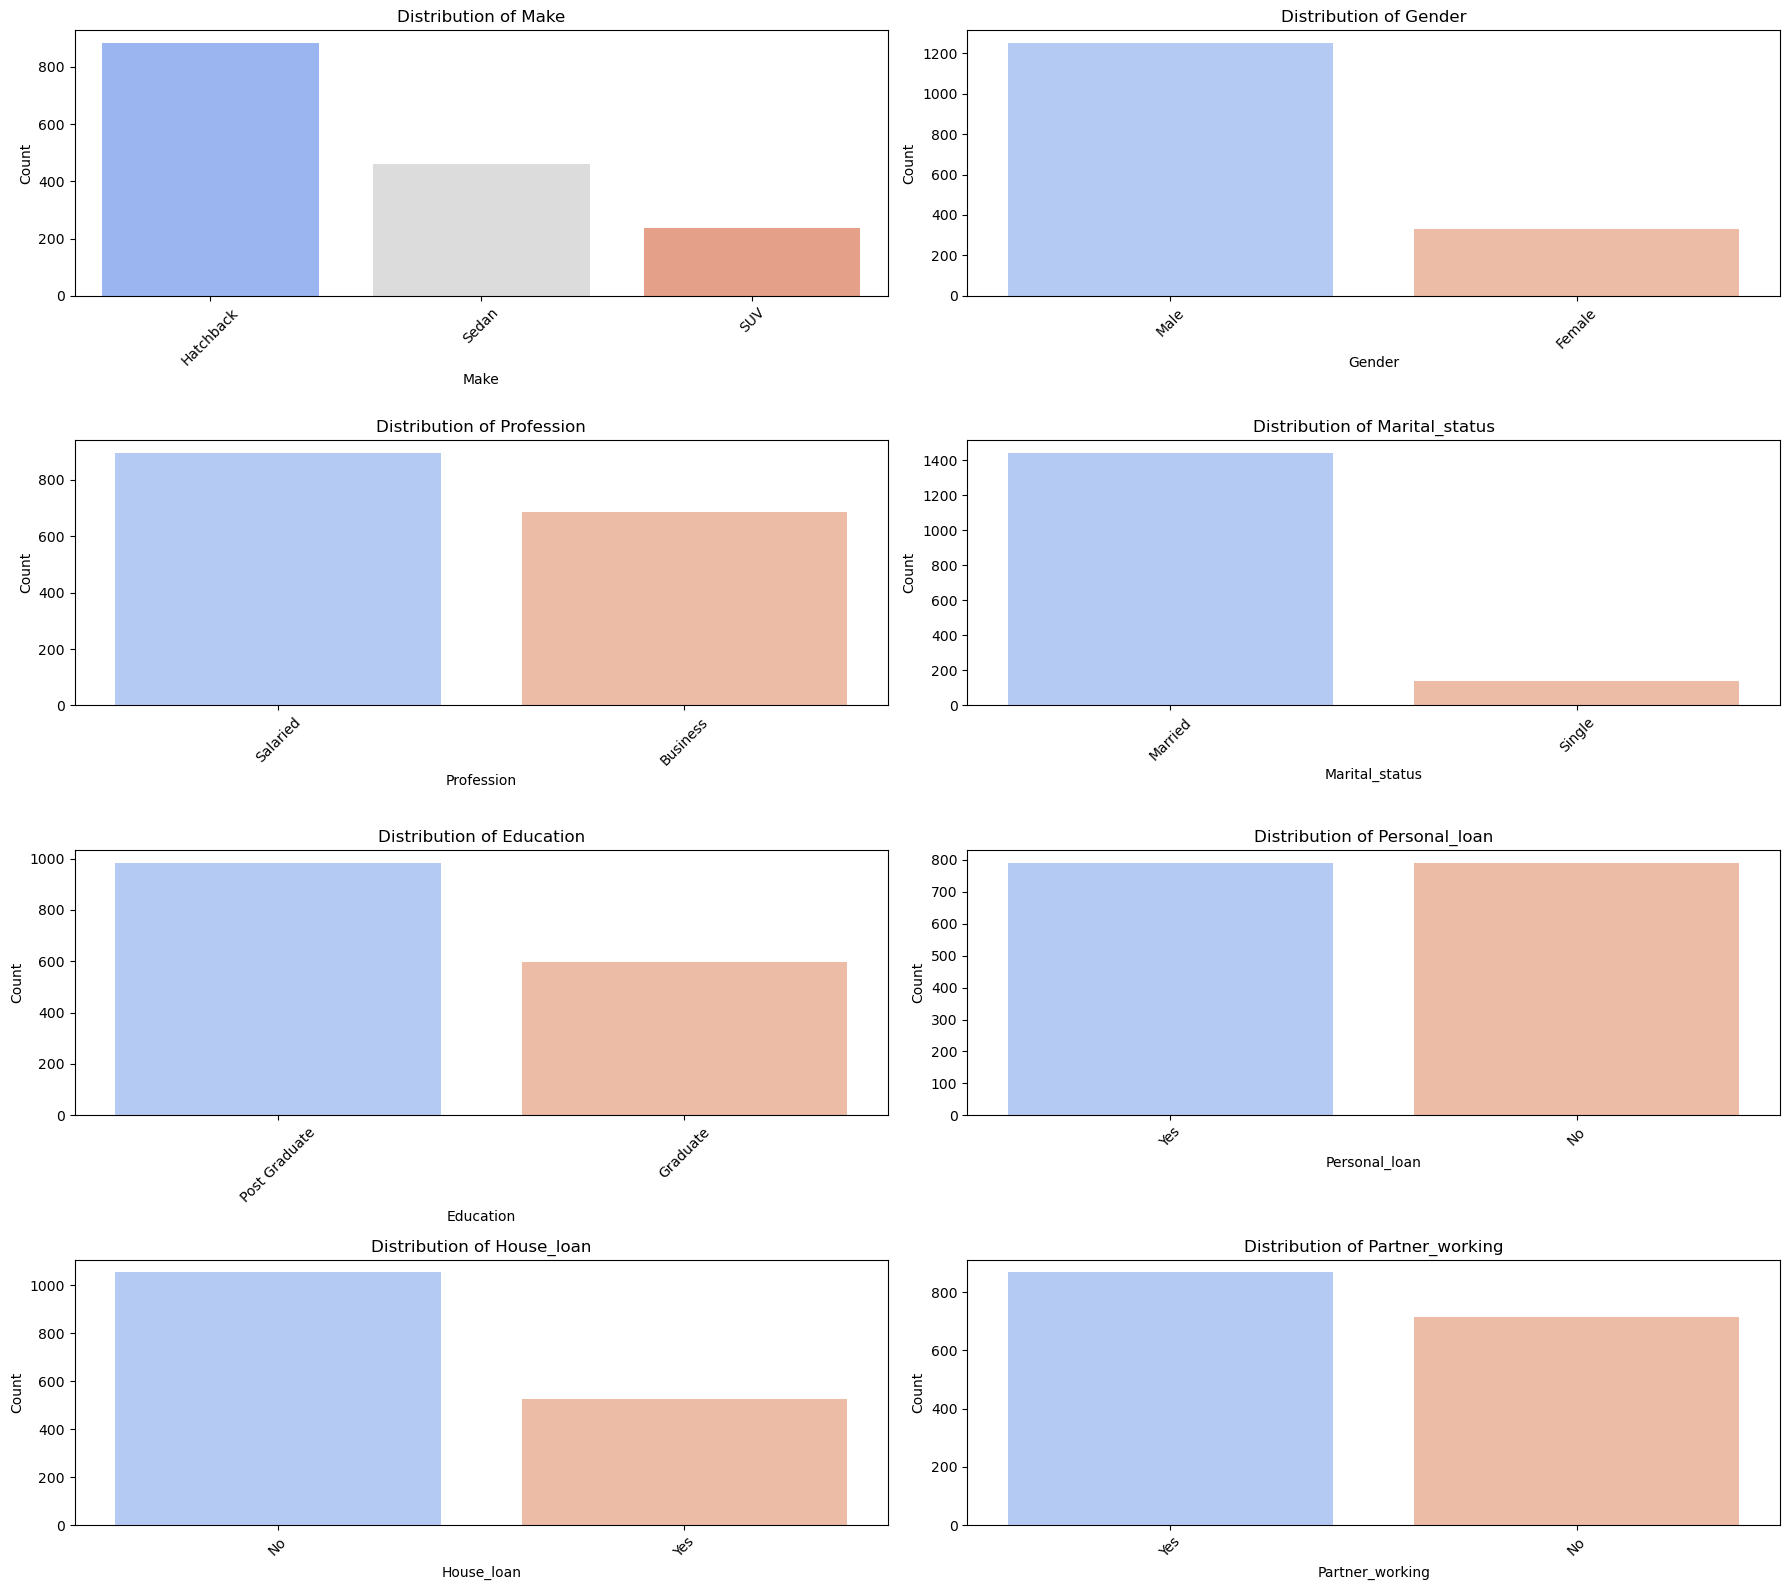

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Number of plots
n_cols = 2
n_rows = -(-len(categorical_columns) // n_cols)  # Ceiling division

# Set up the plot grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()  # Flatten in case of single row

# Plot each categorical column
for i, col in enumerate(categorical_columns):
    sns.countplot(data=dataset, x=col, ax=axes[i], order=dataset[col].value_counts().index, palette="coolwarm")
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_ylabel("Count")
    
# Hide any extra subplots if columns < grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

###  1. Personal Loan Distribution by Gender
This plot shows how personal loan uptake varies between genders. It helps identify gender-based financial behavior or loan access disparities.

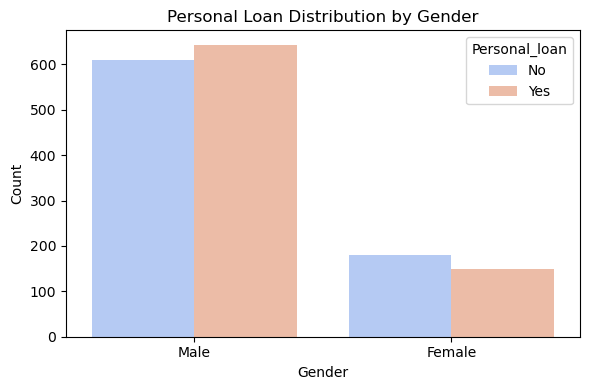

In [20]:
# Personal Loan Distribution by Gender

plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x='Gender', hue='Personal_loan', palette='coolwarm')
plt.title('Personal Loan Distribution by Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

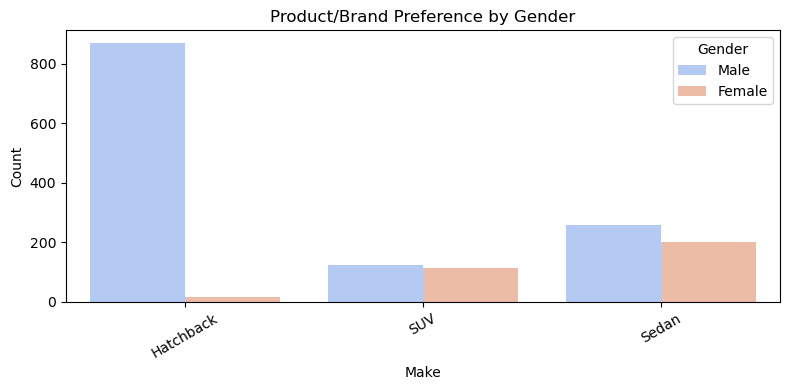

In [21]:
plt.figure(figsize=(8, 4))
sns.countplot(data=dataset, x='Make', hue='Gender', palette='coolwarm')
plt.title('Product/Brand Preference by Gender')
plt.xticks(rotation=30)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### 2. House Loan Distribution by Profession
Visualises how access to house loans differs across professions. This can reveal which job groups are more likely to secure housing finance

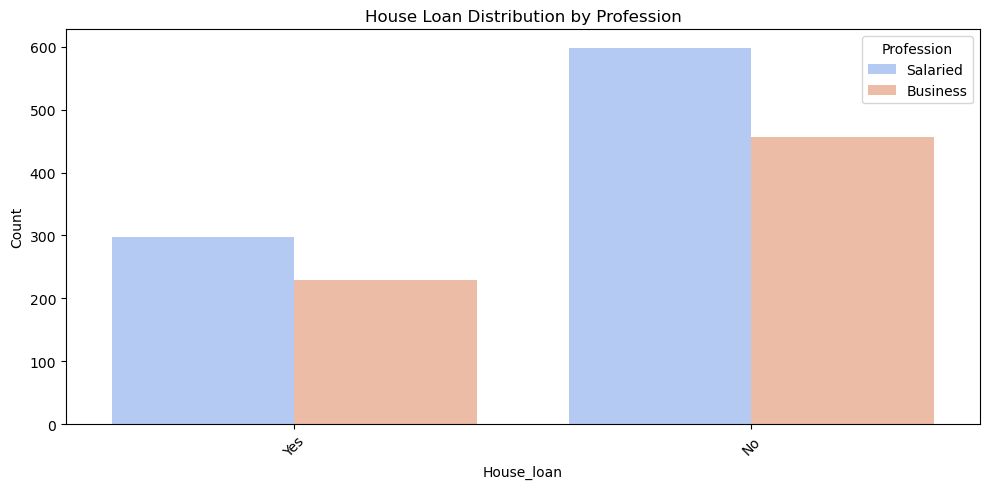

In [23]:
plt.figure(figsize=(10, 5))
sns.countplot(data=dataset, x='House_loan', hue='Profession', palette='coolwarm')
plt.title('House Loan Distribution by Profession')
plt.xticks(rotation=45)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Brand Preference by Gender
Highlights differences in brand (Make) preference across genders. This will reveal consumer behaviour or brand targeting effectiveness.

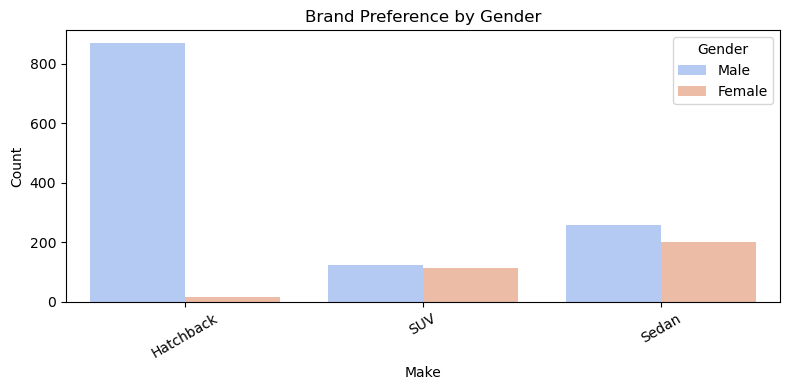

In [25]:
plt.figure(figsize=(8, 4))
sns.countplot(data=dataset, x='Make', hue='Gender', palette='coolwarm')
plt.title('Brand Preference by Gender')
plt.xticks(rotation=30)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Data Cleaning and Preprocessing

Before applying any machine learning model, we must ensure the dataset is clean and properly formatted. This involves:

    Handling missing values
    Encoding categorical variables
    Normalising or scaling numerical features
    Splitting data into training and test sets

# Handle Missing Values

In [28]:
# Check for missing values again
print("Missing values per column:")
print(dataset.isnull().sum())

Missing values per column:
Age                 0
Gender              0
Profession          0
Marital_status      0
Education           0
No_of_Dependents    0
Personal_loan       0
House_loan          0
Partner_working     0
Salary              0
Partner_salary      0
Total_salary        0
Price               0
Make                0
dtype: int64


In [29]:
columns_to_check = ['Age', 'No_of_Dependents', 'Price', 'Total_salary']

# Check max and min
for col in columns_to_check:
    print(f"{col} - Min: {dataset[col].min()}, Max: {dataset[col].max()}")

Age - Min: 22, Max: 60
No_of_Dependents - Min: 0, Max: 4
Price - Min: 18000, Max: 70000
Total_salary - Min: 30000, Max: 158000


## Feature Engineering: Binning and Encoding

To enhance interpretability and help our model detect non-linear patterns, we grouped some continuous features into categorical bins and encoded them for analysis. This is especially useful for logistic regression, which assumes linearity between the independent variables and the log-odds.

Steps and Explanation:

    Age Grouping
    Binned ages into decades (20s, 30s, 40s, 50s) to examine behavioural differences across life stages.

    Dependents Grouping
    Transformed the number of dependents into None, 1-2, or 3+ to simplify relationships.

    Price Range
    Grouped the Price of automobiles into Low, Medium, and High segments.

    Salary Buckets
    Categorised Total_salary into defined ranges for better socioeconomic insight.

    Label Encoding
    Used LabelEncoder to convert the new categorical columns into numeric values.

In [31]:
from sklearn.preprocessing import LabelEncoder

# Age Bins
dataset['Age_Group'] = pd.cut(dataset['Age'], 
                               bins=[20, 30, 40, 50, 60],
                               labels=['20s', '30s', '40s', '50s'])

# Dependents Bins
dataset['Dependents_Group'] = dataset['No_of_Dependents'].apply(
    lambda x: 'None' if x == 0 else ('1-2' if x <= 2 else '3+')
)

# Price Bins
dataset['Price_Range'] = pd.cut(dataset['Price'],
                                bins=[17000, 30000, 50000, 70000],
                                labels=['Low', 'Medium', 'High'])

# Create salary buckets
salary_bins = [0, 50000, 100000, 158000]
salary_labels = ['Low', 'Medium', 'High']
dataset['Salary_Group'] = pd.cut(dataset['Total_salary'], bins=salary_bins, labels=salary_labels)

# Initialize label encoder
le = LabelEncoder()

# Apply label encoding to new categorical columns
dataset['Age_Group'] = le.fit_transform(dataset['Age_Group'])
dataset['Dependents_Group'] = le.fit_transform(dataset['Dependents_Group'])
dataset['Price_Range'] = le.fit_transform(dataset['Price_Range'])
dataset['Salary_Group'] = le.fit_transform(dataset['Salary_Group'])

## Target Variable Transformation

To fit a logistic regression model, we must convert the categorical labels "Yes" and "No" into numeric binary labels:

    1 for "Yes" (positive class — loan taken)

    0 for "No" (negative class — loan not taken)

In [33]:
# Convert 'Yes' to 1 and 'No' to 0
dataset['New_House_loan'] = dataset['House_loan'].map({'Yes': 1, 'No': 0})
dataset['NPersonal_loan'] = dataset['Personal_loan'].map({'Yes': 1, 'No': 0})

In [34]:
dataset.head(5)

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make,Age_Group,Dependents_Group,Price_Range,Salary_Group,New_House_loan,NPersonal_loan
0,24,Male,Salaried,Married,Post Graduate,4,No,Yes,Yes,52000,25000,77000,18000,Hatchback,0,1,1,2,1,0
1,28,Male,Salaried,Married,Post Graduate,3,No,Yes,No,68000,0,68000,18000,Hatchback,0,1,1,2,1,0
2,23,Male,Salaried,Married,Graduate,4,Yes,Yes,No,31000,0,31000,18000,Hatchback,0,1,1,1,1,1
3,26,Male,Business,Married,Post Graduate,4,Yes,Yes,Yes,66000,35000,101000,18000,Hatchback,0,1,1,0,1,1
4,28,Male,Business,Married,Post Graduate,4,Yes,No,No,64000,0,64000,18000,Hatchback,0,1,1,2,0,1


##  Target Variable Class Distribution (New_House_loan)

Before modeling, it’s important to understand if the classes (1 = has house loan, 0 = no house loan) are balanced or imbalanced.

In [36]:
# Calculate frequency of each class in the target variable
class_counts = dataset['New_House_loan'].value_counts()
print(class_counts)

New_House_loan
0    1054
1     527
Name: count, dtype: int64


### Pie Chart to Visualize Class Proportion

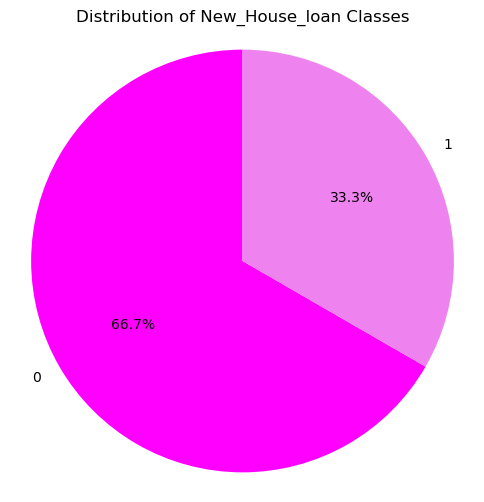

In [38]:
# Labels and sizes
labels = class_counts.index
sizes = class_counts.values

# Plotting the pie chart
plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['magenta', 'violet'])
plt.title("Distribution of New_House_loan Classes")
plt.axis('equal')  # Ensures the pie is a circle
plt.show()

## 1. Feature and Target Selection

In [40]:
features = ['Age_Group', 'Dependents_Group', 'Price_Range', 'Salary_Group']
target = 'New_House_loan'

X = dataset[features]
y = dataset[target]

## 2. Train-Test Split with Stratification

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 3. Handle Class Imbalance with SMOTE

In [44]:
# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

## 4. Train Logistic Regression Model

In [46]:
# Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_resampled, y_resampled)

LogisticRegression(max_iter=1000)

## 5. Predict & Evaluate Performance

In [48]:
# Predict and evaluate
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.37      0.51       211
           1       0.40      0.84      0.54       106

    accuracy                           0.53       317
   macro avg       0.61      0.61      0.53       317
weighted avg       0.68      0.53      0.52       317



## Random Forest after Logistic Regression?

We first used logistic regression because it is a simple and interpretable model. It helps us quickly understand the relationship between the features and the target (New_House_loan).

Now we are using Random Forest as the next step because it is more powerful. It can capture non-linear patterns and interactions between features that logistic regression might not detect. Random Forest also handles categorical features well, especially after encoding, and it is more robust to outliers and noise.

This step allows us to see if a more advanced model can improve prediction performance using the same features

### 1. One-Hot Encode the Features

In [51]:
X_encoded = pd.get_dummies(X, drop_first=True)

# Then use encoded version in train-test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, stratify=y, random_state=42)

## 2. Split the Data and Train a Random Forest Model

In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

## 4. Predict & Evaluate

In [55]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.50      0.60       211
           1       0.41      0.68      0.51       106

    accuracy                           0.56       317
   macro avg       0.58      0.59      0.56       317
weighted avg       0.64      0.56      0.57       317



## Model Evaluation using ROC Curve and AUC

In this step, we evaluated the performance of our trained classification model using the Receiver Operating Characteristic (ROC) curve and the Area Under the Curve (AUC).

In [57]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class
y_scores = model.predict_proba(X_test)[:, 1]

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Compute AUC
roc_auc = roc_auc_score(y_test, y_scores)
print(f"AUC: {roc_auc:.3f}")

AUC: 0.619


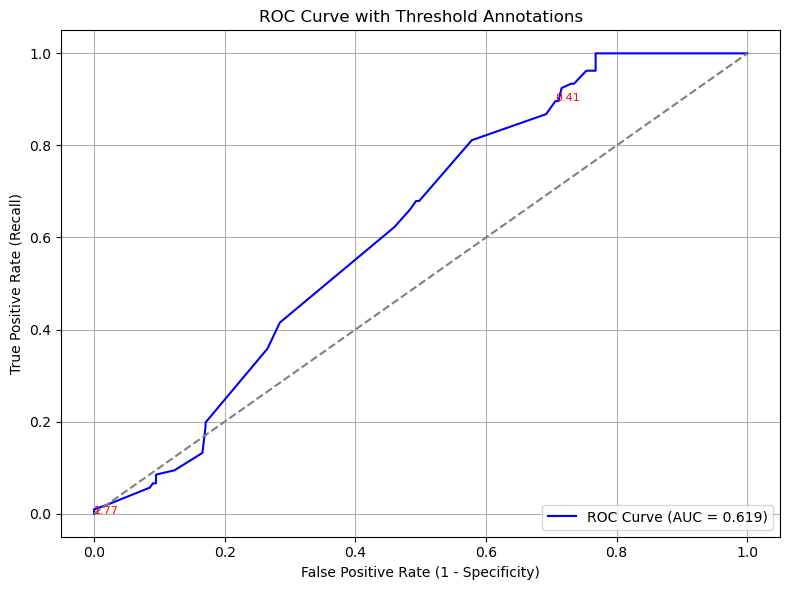

In [58]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

# Optional: Add threshold markers on ROC curve
for i in range(0, len(thresholds), 20):  # every 20th threshold
    plt.annotate(f'{thresholds[i]:.2f}', (fpr[i], tpr[i]), fontsize=8, color='red')

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve with Threshold Annotations')
plt.legend(loc='lower right')
plt.grid()
plt.tight_layout()
plt.show()

## Conclusion

In this project, we developed and evaluated a classification model to predict whether individuals are likely to take up a new house loan based on available features in the dataset. We began with exploratory data analysis to understand class distribution and trends. Then, we applied Logistic Regression as a baseline model and later introduced Random Forest Classifier to enhance prediction performance, especially in handling class imbalance and capturing non-linear relationships.

We assessed model performance using various metrics, including the classification report, confusion matrix, and ROC-AUC. The Random Forest model yielded improved results and better interpretability of feature impact. The ROC curve and AUC provided insights into the model's ability to differentiate between loan takers and non-takers at different thresholds.

This process demonstrates how combining multiple evaluation techniques helps validate model reliability and guides better decision-making in loan risk profiling or targeted financial offerings.